
## 1. 추천 시스템 기초  
> 추천 시스템이란? 사용자의 행동 기록과 아이템 정보를 바탕으로, 사용자가 좋아할 만한 아이템을 예측해 골라 주는 시스템  
*e.g. 넷플릭스 메인 화면의 "회원님이 좋아할 만한 콘텐츠", 유튜브의 다음 영상 목록*

**추천 시스템이 필요한 이유?**  

- 고객 입장 : 찾는 시간과 노력이 줄고, 몰랐던 취향의 아이템도 발견 가능  

- 기업 입장 : 이용시간, 구매 전환, 재방문 증가 가능, 잘 안보이던 비인기 아이템을 노출 가능  


### 1-1 추천 시스템과 데이터 유형  

1. 명시적 데이터(Explicit Data) : 고객들에 의해 입력된 데이터  
    *e.g. 별점, 좋아요/싫어요, 리뷰*   

- 장점 : 비교적 분명한 선호와 불호 -> 사용자 취향 정확히 반영 가능  

- 단점  
    - 평가를 남기는 사람이 적고, 님기더라도 본 것중 일부만 남김 -> 명백한 데이터 수집이 어려움  
    - 사람의 취향은 변하기때문에 과거와 현재의 선호도가 동일한지 알 수 없음  
    - 사람마다 점수의 기준이 다름  


2. 암시적 데이터(Impliciy Data) : 고객들의 행동을 기반으로 수집된 데이터  
    *e.g. 조회수, 클릭, 구매, 시청 시간, 검색*   

- 장점 ; 사용자가 따로 입력하지 않아도 대량으로 쌓여 얻기 쉬움  

- 단점 : 행동이 곧 선호라고 단정 불가  
    - 행동이 있어도 잘못 클릭 or 선물로 구매(좋아한다는 보장 X)  
    - 행동이 없어도 아직 아이템을 못봤을 가능성(싫어한다는 보장 X)  

-> 실제 서비스에선 암시적 데이터가 훨씬많아 둘을 섞어서 사용 


### 1-2 추천 시스템 분류   

분류 기준 : 무엇을 근거로 추천하느냐
1. 내용(콘텐츠)기반 필터링 -> 아이템 유사도  
    - 콘텐츠의 유사도를 기반으로 사용자에게 추천  
    - 사용자가 이용하거나 선택한 아이템과 특징이 비슷한 아이템을 추천하는 방식  
        *e.g. SF영화를 자주 봄 -> 다른 SF 영화 추천*  

2. 협업 필터링 -> 다수 사용자의 행동 패턴   
    - 서비스 내에 있는 다수의 사용자로부터 얻은 선호도 정보를 기반으로 사용자에게 추천  
    - 두 사용자의 취향이 비슷하면, 한 사람이 좋아한 아이템을 다른 사람도 좋아할 가능성이 높다고 봄  

    **이때 비슷함의 기준은?**  
    1. 사용자 기반 (User-Based Filtering) : 특정 사용자와 유사한 취향의 사용자가 선호한 아이템 추천  
    2. 아이템 기반 (Item-Based Filtering) : 사용자가 선호한 아이템과 유사한 아이템 추천  

3. 하이브리드 -> 두 시스템의 조합  
    - 2가지 이상의 다양한 종류의 추천 시스템 알고리즘을 조합해 만들어진 방식  
    - 콘텐츠 기반 필터링과 협업 필터링 각각의 단점들 보완을 위해 제시  

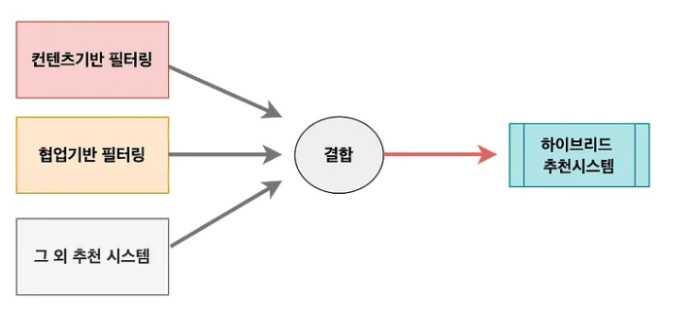  



## 2. 내용 기반 필터링(Content-Based Filtering)  

내용 기반 필터링이 작동하기 위해선 사용자가 무엇을 좋아하는지(사용자 프로필), 아이템끼리 얼마나 비슷한지(유사도)가 필요  

**핵심 흐름** : 아이템을 숫자로 표현 -> 사용자 프로필 생성 -> 유사도 계산 -> 점수가 높은 아이템 추천  


### 2-1 사용자 프로필     
> 사용자 프로필? 사용자가 어떤 특성을 좋아하는지 정리한 정보  

- 추천 시스템에 사용되는 데이터 종류  
    1. 직접 지정형 : 사용자가 자신의 취향을 직접 알려주는 방식  
        - *e.g. 음악 앱 가입시 좋아하는 가수, 장르 선택하게하는 것*  

    2. 간접 지정형 : 사용자의 과거 행동 이력에서 취향을 추론하는 방식  
        - *e.g. 히어로 영화를 종하하는 사람에게 스파이더맨을 추천*  

- 사용자의 프로필 획득 방식  
    1. 사용자가 가지고 있는 아이템 특성 가중치의 평균 값 활용  
    2. 설문, 키워드 입력, 평가등의 방법으로 사용자 기호 파악  
        - 명시적 피드백(좋아요/싫어요, 평점, 댓글) , 암시적 피드백(검색 로그, 구매, 방문한 페이지) 활용
    3. 유저 평가를 바탕으로 분류(Classification)문제로 해결  
        - 아이템에 대한 유저의 기존평가를 정답라벨로 사용하여 새 아이템에 유저가 어떤 평가를 줄지 예측  

### 2-2 유사도  
> 유사도(Similarity)? 두 대상이 얼마나 비슷한지 나타내는 숫자  
- 아이템 정보(텍스트, 이미지, 영상 등)를 숫자 벡터로 변환후 유사도 계산  
- 사용자와 아이템을 같은 기준(feature)으로 표현해야 서로 비교 가능  
- 사용자가 선호하는 아이템과 비교해 유사도가 높은 아이템을 선별해 추천  

**유사도 계산 과정**  
1. 아이템을 숫자로 변환  
    - 아이템 정보 활용  
        *e.g. 영화의 장르, 제작 국가, 감독, 출연 배우, 등급 etc...*  
    - 테이블 형태로 데이터 정리
        - 행: 영화 제목 (예: '라라 랜드')  
        - 열: 아이템의 feature  
        - 셀: feature 값  
    - 숫자로 변환 (원-핫 인코딩)  
        - 텍스트 데이터를 숫자 벡터로 변환해 컴퓨터가 이해할 수 있도록  
            *e.g. 장르 (뮤지컬, 액션, 코미디) -> 각각의 장르를 독립적인 feature로 변환*  
        - 속하면 1, 아니면 0 부여 -> [1, 0, 0, 1, ...]  

2. 사용자를 숫자로 변환  
    - 사용자의 취향 파악 : 직접 입력한 프로필 정보, 시청 기록을 통한 간접적 정보  
    - 사용자도 아이템과 동일한 n개의 featrue로 표현  

3. 유사도 계산  
    - 벡터 내적을 활용하여 유사도 계산  

- 유사도 방식 종류  

| 기반 | 명칭 | 설명 |
| --- | --- | --- |
| 집합 | 자카드 유사도 | 아이템 집합 간의 교집합 크기를 이용하여 측정 |
| 각도 | 코사인 유사도 | 아이템의 벡터 사이의 각도를 이용하여 측정 |
| 거리 | 유클리디안 거리 | 아이템의 벡터 사이의 거리를 이용하여 측정 |
| 상관관계 | 피어슨 상관계수 | 아이템의 벡터간 선형 상관 관계를 이용하여 측정 |


### 2-3 TF-IDF(Term Frequency - Inverse Document Frequency)  
> TF-IDF? 특정 문서에는 자주 나오고 다른 문서에는 드문 단어에 높은 값을 주는 방법 
TF : 단어 빈도 - 특정 문서에 자주 나올수록 증가  
IDF : 역문서 빈도 - 그 단어가 등장한 문서 수가 많을수록 감소  

 $TF(d,t)$ : 특정 문서 d에서 특정 단어 t의 등장 횟수  
 $DF(t)$ : 특정 단어 t가 등장한 문서 수  
 n : 전체 문서 수  
 $IDF(d,t) = \log{\frac{n}{1+df(t)}}$  
 $TF - IDF = TF(d,t) \times IDF(d,t)$
-> 이 값이 높을수록 그 단어가 다른 문서보다 해당 문서에서 더 중요한 역할을 한다는 뜻  


### 2-4 내용기반 필터링 장단점   

- 장점
    - 아이템 콜드 스타트 문제 해결 -> 속성만 있으면 신규 아이템도 추천 가능  
    - 내 기록만으로 프로필을 만드므로 다른 사용자의 데이터가 필요 없음  
    - 어떤 feature 때문에 추천했는지 보여 줄 수 있어 추천 이유 설명 용이  

- 단점
    - feature로 담을 수 있는 정보에 한계 존재 -> 속성 정보가 부족하거나 품질이 낮으면 정확도 하락
    - 비슷한 것만 계속 추천 (과도한 특화, Over-specialization) -> 새로운 장르 발견 어려움
    - 기록이 없는 신규 사용자는 추천 어려움 (사용자 콜드 스타트)

> Cold start problem : 충분한 정보가 수집되지 않아 적절한 제품을 추천해주지 못하는 문제  
> - 아이템 콜드 스타트 : 새 아이템에 평가가 없음 -> 내용 기반으로 해결 가능
> - 사용자 콜드 스타트 : 새 사용자의 기록이 없음 -> 내용 기반으로도 해결 어려움


## 3. 협업 필터링  

협업 필터링의 가정 : 과거에 비슷한 선호도를 가진 사용자들은 앞으로도 비슷한 선호도를 가질 가능성이 높다  

### 3-1 메모리 기반 협업 필터링(Memory-Based Collaborative Filtering)  
> 메모리 기반 협업 필터링? 시스템에 저장된 사용자 - 아이템 평점을 그대로 꺼내서 새 아이템의 평점을 예측하는 방법  

1. 사용자 기반(User-based)접근 : 나와 취향이 비슷한 사용자(이웃)의 평점을 활용해 내 평점을 예측하고 추천  
    - 나와 유사도가 가장 높은 사용자 N명을 이웃으로 선정 -> 이웃들의 평점을 유사도로 가중평균해 내가 아직 평가하지 않은 아이템의 평점 예측 (유사도가 높은 이웃일수록 큰 영향) -> 예측 평점이 높은 아이템 추천  
    * 평점 데이터에선 유사도를 구할때 피어슨 상관계수를 많이 사용  

2. 아이템기반(Item-based) 접근 : 내가 평가한 아이템들과 평점 패턴이 비슷한 아이템을 찾아 추천하는 방식  
    - 아이템의 속성이 아닌 사용자들이 그 아이템을 함께 좋아하고 싫어한 패턴으로 유사도 판단  

**User-based VS Item-based**  

| 기준 | 사용자 기반 | 아이템 기반 |
| --- | --- | --- |
| 정확성 | 아이템 수가 사용자 수보다 많을 때 유리 | 사용자 수가 아이템 수보다 많을 때 유리 |
| 공간, 효율성 | 사용자 간 유사도 저장 -> 사용자가 많으면 부담 | 아이템 간 유사도 저장 -> 아이템이 많으면 부담 |
| 안정성 | 사용자 변화의 영향 많이 받음 -> 아이템이 자주 바뀌고 사용자 유입이 적은 환경에 적합 | 아이템 목록이 잘 변하지 않는 환경에서 안정적 |
| 계산 속도 | 추천할 때마다 비슷한 사용자를 새로 찾아야 함 | 아이템 유사도를 미리 계산해 두고 재사용 -> 빠름 |
| 다양성 | 비슷한 사용자가 평가한 독특한 아이템까지 추천 -> 의외성, 참신성이 강점 | 기존에 본 아이템과 비슷한 추천이 많아 다양성은 상대적으로 부족 |
| 활용 예 | 뉴스, 소셜 미디어(알 수도 있는 친구 추천), 음악 추천 서비스 | 아마존 등 사용자가 많은 대형 플랫폼 |  


### 3-2 메모리 기반 협업 필터링의 한계   

1. 희소 행렬 문제 : 주어진 평점, 선호도 데이터가 적을 경우 성능이 저하되는 문제  
- 데이터 희소시 생기는 문제  
    - 두 사용자가 함께 평가한 아이템이 적어 유사도를 믿기 어려움
    - 비슷한 이웃을 찾지 못할시 예측 자체가 어려움  

-> 모델 기반 협업 필터링(Model-based CF)이용 : 이웃을 직접 비교하는 대신, 관측된 평점으로 사용자와 아이템의 특징을 학습해 빈칸을 채우는 방법  

2. 콜드 스타트 문제 : 데이터가 충분히 쌓이지 않아 적절한 추천을 하지 못하는 문제

- 협업 필터링은 행동 기록에만 의존하기 때문에, 기록이 없는 대상에게는 추천 불가능 - 2가지 상황에서 발생가능  
    - 신규 사용자 : 평가 기록이 없어 비슷한 이웃을 찾기 불가
        *e.g. 넷플릭스에 방금 가입한 사용자*  
    - 신규 아이템 : 아무도 평가하지 않아 추천 후보에 오르지 못함, 누군가 처음 평가하기 전까지는 추천되지 않는다는 의미에서 first-rater 문제라고도 불림
        *e.g. 오늘 새로 등록된 영화*  

    -> 가입시 종아하는 장르나 작품 직접 지정하도록, 새 아이템에는 내용기반 필터링을 함께 쓰는 하이브리드 방식, 같은 카테고리 아이템들의 임베딩 평균으로 새 아이템 임시 표현, 인구통계학적 정보 활용  

3. 확장성 문제 : 아이템과 사용자가 계속 늘어날수록 계산량이 커지는 문제(Scalability)  
아이템 하나의 평점 예측시 아이템을 평가한 사용자들과의 유사도를 모두 구해야함 -> 사용자 및 아이템이 늘수록 계산량 증가, 데이터를 샘플링하거나 줄이면 빨라지나 그만큼 추천 품질 하락  

-> KNN 협업 필터링 이용 : 모든 사용자를 쓰지 않고, 유사도가 높은 k명의 이웃만 골라서 예측  
이웃은 예측하려는 아이템을 실제로 평가한 사용자 중에서만 선택  
k가 너무 작으면 소수 의견에 예측이 흔들림, 너무 크면 덜 비슷한 사용자가 섞여 예측이 흐려짐  


### 3-3 모델 기반 협업 필터링   

> 모델 기반 협업 필터링? 관측된 평점 데이터로 예측모델을 학습하고, 데이터의 패턴을 모델의 파라미터에 담아 관측되지 않은 평점을 예측하는 방법  
- 메모리 기반 : 추천이 필요할 때마다 저장된 평점을 직접 비교해 이웃을 찾음  
- 모델 기반 : 평점 데이터를 먼저 압축된 모델로 요약해 두고, 추천은 이 모델만으로 수행  

**동작 과정**   
1. 학습 단계 (Training) : 이미 존재하는 평점을 가장 잘 설명하는 모델의 파라미터를 찾음 → 추천과 별도로 미리 수행하며, 새 데이터가 쌓이면 주기적으로 다시 학습
2. 예측 단계 (Inference) : 학습된 파라미터로 비어 있는 칸의 평점을 계산 -> 추천이 필요한 시점에 빠르게 수행  

**등장 배경**  
메모리 기반 협업 필터링은 평점 사이의 유사도에만 의존 -> 평점에 드러나지 않는 취향의 구조를 포착하지 못함, 희소성과 확장성 문제에 취약

=> 모델 기반 협업 필터링은 평점 이면의 잠재된 패턴을 학습함으로써, 직접 겹치는 평가가 없어도 전체 데이터의 흐름으로 빈칸을 추정하고 추천 시점의 계산을 가볍게 만듦    

**메모리 기반 vs 모델 기반**  

| 구분 | 메모리 기반 | 모델 기반 |
| --- | --- | --- |
| 학습 단계 | 없음 | 있음 |
| 예측에 쓰는 것 | 원본 평점 데이터 | 학습된 모델 |
| 희소한 데이터 | 함께 평가한 아이템이 적어 유사도 근거가 부족 | 전체 패턴을 학습해 빈칸을 일반화 |  

> 잠재요인(Latent Factor) : 평점에 직접 드러나지는 않지만, 사용자와 아이템 사이의 관계를 결정짓는 숨은 특성  
- 모델이 관측된 데이터를 바탕으로 수치적으로 추정하는 값, '취향', '성향'과 같이 실제 데이터엔 없는 개념을 숫자로 표현  

> Latent Factor Model : 사용자와 아이템을 같은 잠재 공간 위의 벡터로 나타내고 두 벡터의 관계로 평점을 설명하는 모델
- 평점 행렬을 사용자-잠재요인 행렬과 아이템-잠재요인 행렬로 나누어 학습  

**Factor model vs Latent Factor model**  
- Factor model : 축(차원)이 무엇을 뜻하는지 사람이 미리 정해둔 공간  
    - 유저와 아이템이 차원이 같은 벡터로 표현되어 같은 공간에 배치가 가능하고, 서로의 유사도 파악 가능  

    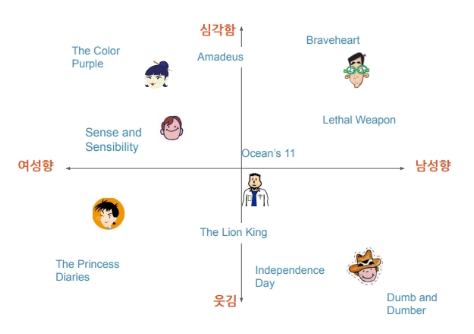  


- Latent Factor model : 축의 개수만 정해두고, 각 축이 무엇을 뜻하는지는 학습으로 정해지는 공간  
    - 축의 의미는 알수없고, 축의 개수를 여러개로 설정 가능  
    - 사용자와 아이템을 같은 공간의 벡터로 놓고, 서로의 거리나 각도등을 통해 유사도 파악 및 잠재적 취향 추정  

    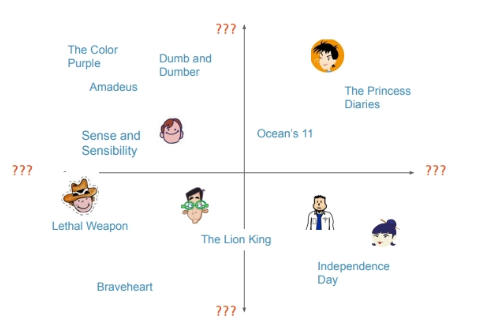  


**메모리기반 vs 모델기반**  

|  | 메모리 기반 | 모델 기반 |
| --- | --- | --- |
| 예측 방식 | 비슷한 사용자와 아이템을 직접 찾음 | 학습한 벡터를 내적 |
| 확장성 | 추천할 때마다 많은 유사도 계산 필요 | 학습은 미리 하고, 추천시 벡터 내적만 계산 -> 빠름 |
| 콜드 스타트 | 해결 어려움 | 해결 어려움 (상호작용이 없으면 벡터 학습 불가) |
| 장점 | 추천 이유 설명이 쉬움 | 데이터를 압축해 예측이 빠르고 일반화에 유리 |  


## 4. VAE 기반 협업 필터링(Variational Autoencoder CF)  

> VAE기반 협업 필터링? 사용자의 상호작용 기록을 신경망으로 확률분포로 압축한 뒤, 다시 복원하면서 아직 보지 않은 아이템의 선호를 예측하는 모델  

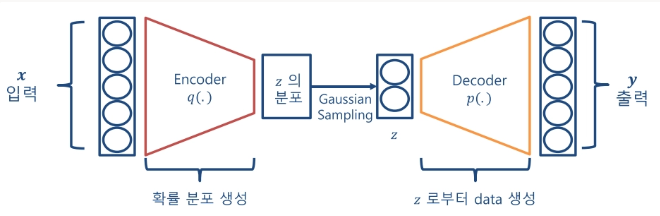  


### 4-1 MF의 한계와 딥러닝의 등장  

#### MF의 한계  

1. 선형성  
행렬분해의 예측은 내적구조, 각 요인이 점수에 따로따로 더해지고, 요인끼리 얽히는 효과는 표현이 어려움  

2. 불확실성 무시  
일반적인 MF는 사용자마다 벡터 하나 학습 - 점 추정(Point Estimate)  
-> 기록이 5개뿐인 사용자와 5000개인 사용자의 벡터를 똑같이 확신하고 사용 -> 기록이 적은 사용자의 추정이 불안정해도 구분 못함  

**해법**  

| MF의 한계 | 내용 | 딥러닝의 해법 |
| --- | --- | --- |
| 선형성 | 예측이 내적 하나로 결정되어 복잡한 조합 패턴 표현이 어려움 | 비선형 활성화 함수를 가진 신경망 사용 |
| 불확실성 무시 | 기록이 적은 사용자와 많은 사용자를 구분 없이 같은 확신도의 벡터 하나로 표현 | 평균과 분산을 함께 출력 |

=> 위 두가지 한계 극복을 위해 도입된 모델 : VAE  

### 4-2 AE vs VAE  

> AE(AutoEncoder)? : 입력을 작은 벡터로 압축했다가 복원하는 신경망 모델  
- 입력을 복원하는데 꼭 필요한 핵심 정보만 남기도록 학습  
- 정답이 없고, 입력 자체가 정답  

> VAE(Variational AE) : 가운대 잠재 벡터를 점 하나가 아닌 분포로 표현하는 AE  

- VAE가 더 안정적인 이유  
    1. 점 하나가 아니라 그 주변을 사용하여 학습  
        학습때마다 $\mu$ 근처에서 z를 무작위로 뽑아 디코더에 입력, 디코더는 $\mu$ 에서 조금 벗어난 위치에서도 비슷한 추천이 나오도록 학습됨  
    2. 기준 분포 쪽으로 당겨짐  
        KL 항이 분포를 표준 정규분포 쪽으로 당기므로, 기록 몇 개만으로 극단적인 위치로 가기 어려움 
        
**AE vs VAE**  

| 구분 | AE | VAE |
| --- | --- | --- |
| 잠재 벡터 표현 | 단일 값 (Point Estimate) | 평균 $\mu$와 표준편차 $\sigma$를 가진 정규분포 |
| 불확실성 반영 | 반영하지 않음 | 사용자별 $\sigma$로 표현 |
| 장점 | 구조가 단순함 | 기록이 적은 사용자에게도 안정적이고 일반화에 유리 |  



### 4-3 VAE기반 CF(Mult-VAE)의 작동 구조  

> Mult-VAE : 사용자의 상호작용 기록(0/1 vector)을 입력받아, 인코더로 취향을 분포 $(\mu, \sigma)$로 요약하고 디코더로 전체 아이템의 선호 확률을 복원해 추천하는 구조  

| 구성 요소 | 세부 내용 |
| --- | --- |
| 입력($x$) | 아이템 수만큼 긴 0/1 벡터로, 평점 데이터는 4점 이상만 1로 바꿔 사용 |
| 인코더 | 평균 $\mu$와 표준편차 $\sigma$를 출력 |
| 잠재 벡터 ($z$) | $\mu$, $\sigma$로 정해진 정규분포에서 샘플링한 벡터 |
| 디코더 | 모든 아이템의 점수를 계산한 뒤 softmax로 확률로 변환 |


### 4-4 목적함수와 KL Divergence  

VAE는 ELBO라는 목적함수를 최대화하며, 이 안에서 정확한 복원과 잠재공간 정규화라는 두가지 목표를 동시에 최적화  

> 목적함수 ELBO(Evidence Lower BOund) : 데이터가 나올 로그 확률 하한(Lower bound)을 키우는 방식  

$\mathcal{L}(x; \theta, \phi) = \underbrace{E_{q_\phi(z|x)} [ \log p_\theta(x|z) ]}_{\text{재구성 오차 최소화 (Reconstruction Loss)}} - \underbrace{D_{\text{KL}}(q_\phi(z|x) || p(z))}_{\text{잠재 공간 정규화 (KL Divergence)}}$  

1. 복원 항 (첫 번째 항)  
- 디코더가 잠재 벡터 $z$를 사용하여 원래 입력 $x$를 최대한 비슷하게 복원하도록 함 (AE의 역할과 동일)  

2. KL Divergence 항 (두 번째 항)  
- 인코더가 출력하는 잠재 분포 $q(z|x)$가 표준 정규분포 $p(z)$ 에서 크게 벗어나지 않도록 강제  
- 이를 통해 일부 사용자 데이터에 대한 과적합을 막고, 잠재 공간이 불규칙해지지 않도록 연속적이고 부드럽게(Smooth) 유지  

> KL Divergence? 두 확률 분포가 얼마나 다른지를 나타내는 값  

$D_{KL}(N(\mu, \sigma^2) || N(0, 1)\big) = \frac{1}{2}(\mu^2 + \sigma^2 - \ln \sigma^2 - 1)$  

사용자의 분포가 $Z$면 0이되고, 평균이 멀어지거나 분산이 지나치게 작거나 크면 값이 증가  

i.e. KL term이 AE와 VAE의 잠재공간 사이의 차이를 만듬  
- AE : 정확하게 복원만 하면 OK -> 벡터들이 제약 없이 흩어질 수 있음
- VAE : 정확하게 복원 + N(0, 1)에서 너무 벗어나지 않도록 패널티 부여 -> 분포들이 중앙 근처에 연속적으로 모임


**VAE-CF의 장점**  
1. 확률적 잠재 분포 모델링 (불확실성 반영)
- 기존 MF처럼 단일 포인트 벡터가 아니라 확률적 잠재 분포로 사용자 선호 모델링, 예측 시의 불확실성 반영 및 노이즈의 영향 줄임

2.  희소한 상호작용 데이터에서도 안정적
- KL Divergence를 통해 잠재 공간을 정규화 -> 기록이 적은 사용자도 비슷한 사용자들 근처에 안정적으로 표현되어 희소성 문제에 효과적으로 대응 가능

3.  비선형성 학습
- 신경망 구조를 통해 MF의 한계였던 복잡하고 비선형적인 패턴을 학습하여 추천 성능 향상


## 5. GNN기반 사용자 선호 예측  

### 5-1 GNN(Graphic Neural Network)  

사용자 - 아이템 상호작용은 본질적으로 그래프  
사용자, 아이템 : 점 / '봤다', '샀다' : 선(행동)  
GNN은 사용자와 아이템의 상호작용을 서로 연결된 거대한 관계망으로 형성  

### 5-2,3 GNN 구조 및 프로세스

**GNN의 작동 구조**  

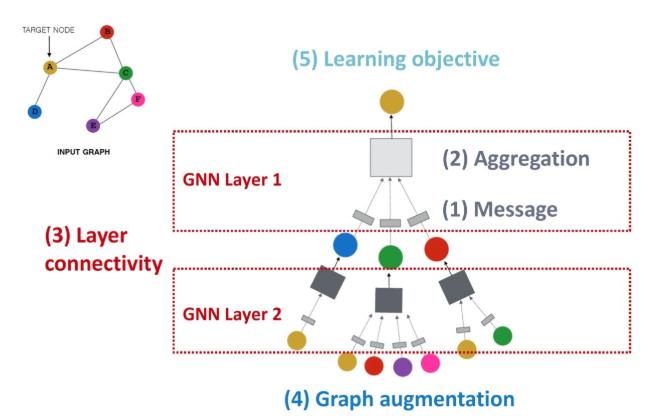  

1. 그래프 구조 생성 : 노드, 엣지 정의 및 각 노드에 초기 피처(임베딩) 부여  

2. 메시지 패싱 : 각 노드가 이웃 노드로부터 정보를 받아 전달  
    하나의 GNN레이어는 '메시지 생성 - 집계 - 갱신'의 3단계로 구성, GNN이 k개의 레이어로 구성되어 있다면 이 과정이 k번 반복  
    임베딩을 갱신하는 대상노드 : 타겟 노드, 모든 노드가 한 번씩 타겟 노드가 됨  
    1. 메시지 생성 : 각 노드가 이웃에게 보낼 자신의 정보 생성(임베딩), 메시지 함수 사용    
    2. 집계 : 타깃 노드가 받은 메시지들을 하나의 벡터로 합침 (평균, 합, 최대값, attention 등)  
    3. 갱신 : 집계 결과와 자신의 이전 임베딩을 결합해 새 임베딩을 생성  
        이 과정을 $l$번 반복하여 $l$단계만큼 떨어진 이웃의 정보 반영  

3. 최종 출력  

=> 내 이웃노드(나와 비슷한 사용자, 내가 본 아이템)의 정보를 나에게 전달/요약(Message Passing)  


### 5-4 LightGCN(Light Graph Convolutional Networks)  

GNN아키텍처들의 차이는  
1. 메시지를 어떻게 만드는가  
2. 메시지를 어떻게 합치는가  로 결정  

**주요 GNN 아키텍처 정리**

| 아키텍처 | 작동 방식 | 특징 |
| --- | --- | --- |
| GCN (Graph Convolutional Network) | 이웃 임베딩을 연결 수(차수)로 정규화해 평균 | 가장 기본적인 구조, 학습 시 전체 그래프 필요 |
| GRN (Graph Recurrent Network) | RNN 구조를 GNN에 결합 | 시간에 따라 변하는 그래프(동적 관계) 포착 |
| GAT (Graph Attention Network) | 이웃마다 attention으로 중요도를 학습해 가중 평균 | 중요한 이웃에 집중하지만 계산량 증가 |
| GraphSAGE | 이웃을 일부만 샘플링하고, 이웃 정보를 더하지 않고 자기 정보와 concat | 대규모 그래프와 학습 때 없던 새 노드에도 적용 가능 |  

GNN : 그래프 데이터를 학습하는 신경망 전체를 가리키는 개념
GCN : GNN 중 합성곱(Convolution) 연산으로 이웃 정보를 집계하는 구체적인 모델  
추천시스템에서 가장 널리 쓰이는 계열은 GCN, 이를 사용자-아이템 그래프에 적용한 NGCF제안 -> 이를 단순화한게 LightGCN  

#### LightGCN 

**탄생배경**  
NGCF는 노드 분류용 GCN의 연산을 그대로 사용해, 레이어마다 가중치 행렬 W를 곱하고 비선형 활성화 함수 적용  

이 두 연산은 노드마다 텍스트나 속성 같은 풍부한 피처가 있을 땐 유용하지만 추천 그래프의 노드에는 사용자 ID와 아이템 ID에 해당하는 ID 임베딩만 존재. 실제로 LightGCN 연구 결과, 두 연산은 추천 성능에 도움이 되지 않았고 오히려 학습을 방해  

=> LightGCN은 두 연산을 제거 및 추천의 핵심인 사용자-아이템간 연결관계만 전달하도록 구조를 단순화  

**제거한 2가지 요소**  
1. 특징 변환(Feature Transformation)
    - 레이어마다 복잡했던 학습 파라미터 ($W^{(l)}$) 삭제
2. 비선형 활성화 함수 (Non-linear Activation) 제거
    - ReLU와 같은 활성화 함수를 사용하지 않고, 이웃 정보를 합침 -> 주로 정규화된 합 or 평균 사용

⇒ LightGCN은 '정규화된 이웃 임베딩의 합 + 레이어 결합'만으로 구성된 가볍고 효율적인 모델


### 5-5, 5-6 GNN활용 사례 및 장단점

#### GNN활용 사례  
- SNS(Pinterest),  
- 소셜 네트워크(서로 알고 있는지, 어떤 경로로 알고 있는지 카테고리화, 추천친구목록에 뜨려면 엣지로 얼마나 가까워야 하는지)  
- 금융 및 보안 : 이상 거래 탐지, 악성 사용자 분류  
- Traffic : 한 장소에서 다른장소까지 시간 소요 계산  
- 프로그램 분석 : 프로그램 내에서 코드에 대해 auto suggestion  

#### 장단점  
- 장점  
    1. 고차원 협업 시그널 (High-order Collaborative Signals) 포착  
        단순히 '나'의 잠재 요인(MF, VAE) 분석을 넘어, 나와 취향이 비슷한 사용자들(이웃)과 내가 본 아이템과 연관된 다른 아이템들의 정보를 직접 반복해서 반영 가능  

    2. 정형화되지 않은 데이터 학습 가능  
        GNN은 ‘관계’를 학습하기 때문에, 상호작용, 소셜 관계, 지식 그래프, 사용자 속성을 하나의 그래프에 함께 담아 학습 가능  

    3. Cold Start 문제 완화에 효과적  
        상호작용이 없는 신규 아이템도 속성 노드나 이웃 정보를 통해 임베딩을 얻을 수 있음   

- 단점  
    1. 과평탄화 (Over-smoothing) 문제 : 모든 노드의 임베딩이 같은 값으로 수렴하는 현상  
        메시지 전달을 많이 반복하여 GNN 모델의 레이어가 많아질수록, 연결된 그래프 내의 모든 노드 간의 임베딩이 비슷해지는 문제가 발생
    
    2. 과압축 (Oversquashing) 문제  
        단계마다 기하급수적으로 늘어나는 이웃 정보를 고정 크기 벡터에 담으면서 먼 노드의 정보가 손실  

    3. 계산 복잡도 증가  
        실제 세계에서는 수십억 개의 노드와 엣지가 포함된 그래프에 GNN을 적용해야 하므로 막대한 자원과 메모리 필요  
    
    4. 순서 반영의 어려움  
        GNN은 모든 상호작용을 집합으로 보지만, 순서 반영은 불가. '신발 -> 바지 -> 셔츠' 순서로 구매한 것과 '셔츠 -> 바지 -> 신발' 순서로 구매한 것이 같은 그래프가 되어, 다음 행동을 예측하기 어려움


## 6. Transformer기반 추천 시스템  

### 6-1 기존 추천 시스템의 한계   

1. CF의 순차적 한계  
    - 순서 무시 : 같은 아이템을 사면 구매 순서가 달라도 같은 사용자로 봄  
    - 문맥 부족 : 방금 한 구매와 1년 전 구매의 중요도를 구분 못함  
    - 예측의 한계 : '다음' 행동보다는 '일반적인' 선호를 예측하는 데 초점을 둠  

2. GNN의 순차적 한계   
    - 지역적 정보 전파의 한계  
        - A -> B -> C에서 C가 A의 정보를 받으려면 반드시 B를 거쳐야 함(레이어 2개 필요)  
        - 거치는 동안 정보가 희석되고 압축됨(과압축 문제)  
    - 장기 의존성 문제  
        - GNN은 레이어 수만큼의 단계까지만 볼 수 있어서, 멀리 떨어진 행동 간의 관계를 잘 포착하지 못함
        - 반면, Self-Attention은 시퀀스 안의 모든 아이템 쌍을 거리와 상관없이 한 번에 직접 비교  

->  CF : '누가 무엇을 좋아하는가', GNN : '무엇이 무엇과 연결되어있는가' 포착 but, 둘 다 사용자가 '어떤 순서로, 어떤 의도로' 행동하는지 파악 불가  

=> 시퀀스 전체를 한번에 보며 지금 맥락에 중요한 과거행동에 집중하는 Transformer model이 대한으로 등장!  


### 6-2, 6-3 Transformer / Self-Attention  

같은 사용자라도 세션마다 탐색하는 상품군이 다름.  
다음 행동은 장기적인 평균 취향보다 최근 행동의 순서와 조합(문맥)에 더 큰 영향을 받음  

- Example1 : '문맥'에 따라 달라지는 동일 아이템의 의미(Self-Attention)  

1. 수영복, 비치타월과 함께 등장하는 선크림  
    휴가 준비물이라는 판단 -> 다음 추천 결과 : 방수팩, 래시가드 ...  

2. 스킨, 로션과 함께 등장하는 선크림  
    데일리 스킨케어로 판단 -> 다음 추천 결과 : 클렌징폼, 선크림 리필...  

즉, 같은 아이템이라도 앞에 등장한 아이템에 따라 목적이 다르게 해석되고, 다음추천도 변화  

- Example2 : 시간 순서를 뛰어넘는 '핵심의도' 포착(Long-Range Dependency)  
다음 행동과 관련된 아이템이 가장 최근이 아니라 시퀀스 앞부분에 있는 경우도 존재  
Transfoermer는 현재시점과 과거 모든 아이템의 관련성을 한번에 계산하므로 거리에 관계없이 가중치 부여 가능(순차적으로 정보를 전달하는 RNN, GNN은 앞단계 정보가 희석됨)  

-> 두 예시 모두, 현재 아이템과 다른 아이템 간의 관련성을 계산해, 관련성이 높은 아이템의 정보를 더 많이 반영하는 방식으로 동작, 이 연산이 Self-Attention

> Self-Attention : 시퀀스 안의 모든 아이템 쌍의 관련성을 거리와 상관없이 동시에 계산 -> 중간에 많은 행동이 끼어있어도 둘을 직접 연결가능하여 장기의존성 문제 해결 가능  

**동작 원리** : Self-Attention은 시퀀스의 각 아이템 임베딩을 3가지 벡터로 변환해 사용  

| 개념 | 정의 | 역할 |
| --- | --- | --- |
| Query (Q) | 아이템 임베딩 × 가중치 행렬 $W_Q$ | 현재 아이템이 다른 아이템과의 관련성을 계산하는 기준 |
| Key (K) | 아이템 임베딩 × $W_K$ | Query와 내적되어 관련성 점수를 결정 |
| Value (V) | 아이템 임베딩 × $W_V$ | 관련성 점수에 따라 가중합되는 실제 정보 |

**연산과정** : '관련성'을 계산하여 '가중치'생성  

1. Attention Score 계산 $(Q \cdot K)$  
    - 선크림의 Query와 각 아이템의 Key 내적, 관련성 점수 계산  
    *e.g. 수영복 2.0 / 비치타월 1.5 / 양말 0.1*  
2. 가중치 변환 (Softmax)
    - 점수를 합이 1이 되는 비율로 변환
    -> 수영복 57.0% / 비치타월 34.5% / 양말 8.5%
3. 가중합 $(Score \cdot V)$
    - 각 아이템의 Value에 비율을 곱해 합 계산
    - 선크림의 출력 = 0.570 × V(수영복) + 0.345 × V(비치타월) + 0.085 × V(양말)  

-> 선크림의 출력 벡터는 수영복과 비치타월의 정보가 92%차지 = '휴가 준비물'로 해석  
i.e. 관련성에 따라 정보 반영 비율을 다르게 적용하는것이 Self-Attention  


### 6-4 Transformer기반 주요 추천 시스템 모델   

Self-Attention을 추천에 적용한 대표 모델 : SASRec & BERT4Rec  

#### SASRec  

> SASRec? 단방향 어텐션으로 과거 정보만 활용해, 다음 아이템을 예측하도록 학습한 모델  

- 방식 : 단반향 어텐션(GPT와 유사)  
- 어텐션 계산 : 과거 아이템만 참조 가능  
- 목표 : 다음 아이템 예측 (Next-item prediction)
    *e.g. [노트북 -> 마우스 -> 키보드] => 다음은 '노트북 거치대'  
- 특징  
    1. 적응적 집중 : 데이터가 희소하면 최근 아이템에, 풍부하면 긴 과거 맥락에 집중하도록 Attention 조절  
    2. 빠른 학습 : RNN처럼 순서대로 계산하지 않고 모든 위치를 병렬로 처리  
- 문제점  
    1. 계산량 : Attention 연산량이 시퀀스 길이의 제곱$(n^2)$에 비례해, 긴 행동 이력을 다루기는 부담  
    2. 단방향성 : 과거 방향만 참조하므로 시퀀스 앞부분의 아이템은 활용할 정보가 적음. 또한 장바구니에 동시에 담은 물건처럼, 실제 행동 순서가 엄격하지 않은 경우도 존재  

=> 이 중 단방향성 문제를 보완하기 위해 등장한 모델이 BERT4Rec!  

#### BERT4Rec  

> BERT4Rec? 양방향 어텐션으로 과거와 미래 정보를 모두 활용해 가려진 아이템을 예측하도록 학습한 모델  

- 방식 : 양방향 어텐션 (BERT와 유사)  
- 어텐션 계산 : 시퀀스 일부를 [mask] 토큰으로 가리고, 가려진 위치가 과거와 미래의 모든 아이템을 참조 가능
    - [MASK] 로 가리는 이유? 모델이 양방향으로 학습하면서 target 아이템의 정보를 직접 보게 되는 **정보 누출(information leakage)**이 발생할 수 있기 때문!
- 목표 : 가려진 아이템 예측 (Masked-item prediction)  
    *e.g. [노트북 -> 마우스 -> [MASK] -> 키보드] => 앞뒤 문맥으로 [MASK] = '노트북 거치대' 예측  
- 특징 :  
    1. 양방향 문맥 : 각 아이템의 앞뒤 문맥을 모두 학습에 사용  
    2. 데이터 활용 : 한 시퀀스에서 가리는 위치를 바꿔 가며 여러 학습 샘플 생성 가능  

**SASRec vs BERT4Rec**  

| 구분 | SASRec | BERT4Rec |
| --- | --- | --- |
| 어텐션 방향 | 단방향 (과거만) | 양방향 (과거 + 미래) |
| 학습 목표 | 다음 아이템 예측 | 가려진 아이템 예측 |
| 학습 효율 | 빠름 | 상대적으로 느림 |  

**상황별 선택 기준**  

| 상황 | 유리한 모델 | 이유 |
| --- | --- | --- |
| 상호작용이 많고, '다음 행동' 예측이 목적 (실시간 피드, 커머스) | SASRec | 학습, 추론 효율이 높고, 손실 함수를 같게 하면 성능도 동등 이상 |
| 상호작용이 적어 시퀀스가 짧은 경우 | 상황에 따라 다름 | BERT4Rec은 한 시퀀스에서 여러 마스킹 샘플을 만들 수 있어 데이터 증강 효과가 있지만, 손실 함수를 맞추면 차이가 줄어든다는 반론도 존재 |
| 행동 순서가 느슨한 도메인 (장바구니에 동시에 담기 등) | BERT4Rec | 양방향 문맥이 의미 있음 |



## 7. 오늘날의 추천 시스템  

LLM의 등장을 인해 추천시스템에 새로운 변화가 발생  
과거엔 조합별로 미리 학습된 공식에 따라 점수를 출력했다면, LLM이후 추천을 점수계산이 아닌 문장으로 출력하게 됨  

아이템을 텍스트로 이해시 기존 모델로는 어려웠던 두가지가 가능해짐  
1. 대화형 추천 : 사용자가 자연어로 입력한 조건 반영해 추천  
    *e.g. '비오는 일요일에 혼자 보기 좋은, 너무 슬프지 않은 영화 추천해줘'*  
2. Zero-shot 추천 : 상호작용 데이터 없이 텍스트 설명만으로 추천  
    - 신상품 등록 첫날, 구매기록이 없어도 설명만으로 추천대상 가능  
    => Cold-Start문제의 강력한 해결책  
> Cold-Start : 신규 사용자나 아이템의 상호작용 정보가 부족하여 제대로 된 추천이나 예측을 하지 못하는 상황   

**LLM을 추천에 적용하는 방식**  
1. P5(Geng et al., RecSys 2022)  

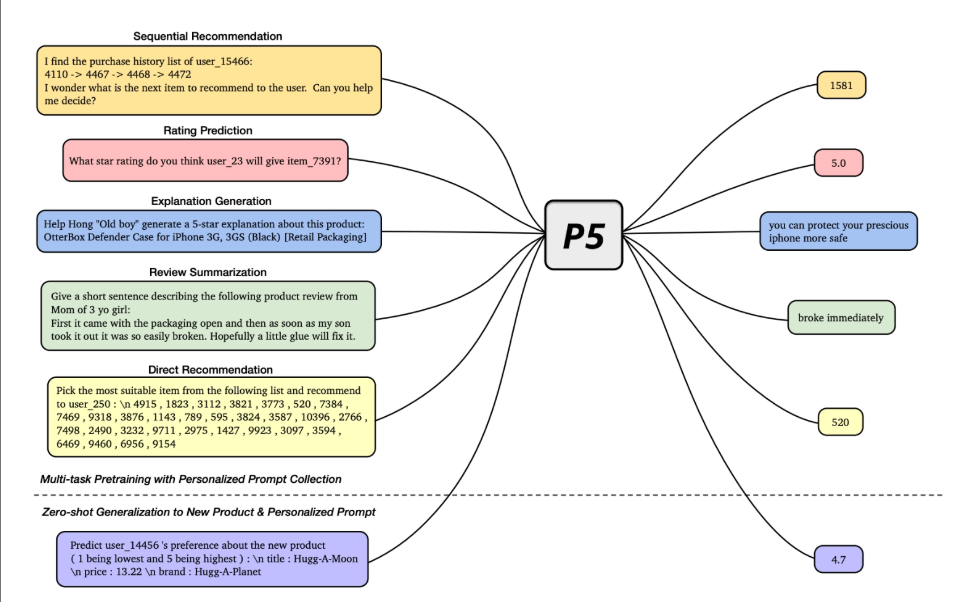  

- 여러 추천 과제를 '텍스트 프롬프트 -> 텍스트 답변' 형식으로 통일하여, 하나의 언어 모델로 학습한 모델   
- (-) 언어 모델을 추천데이터로 처음부터 학습하므로 많은 컴퓨팅 자원과 시간이 필요  


2. TALLRec(Bao et al., RecSys 2023)  

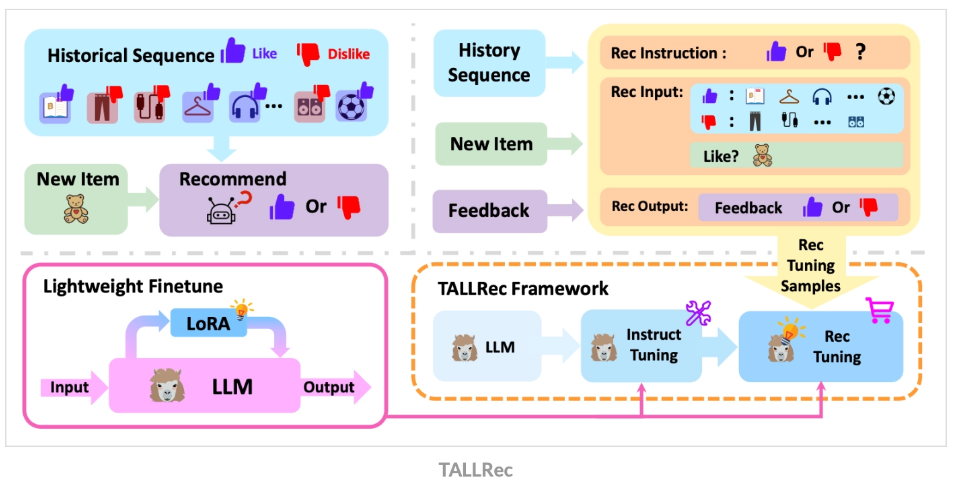  


- 학습 비용을 줄이기 위해, 범용 LLM을 '좋아할까?(Yes/No)' 형식의 추천 지시문으로 튜닝하는 프레임워크  
- LoRA로 일부 파라미터만 학습, 적은 샘플로도 기존 모델보다 높은 성능 보고  

-> LLM은 단순 성능향상뿐만 아니라, 추천 시스템이 사용자와 상호작용하는 방식을 변화시킴  


그러나, 추천 모델이 정교해져도 '무엇을 추천하는가(인기 편향)'와 '왜 추천하는가(설명 가능성)'의 문제는 여전히 존재  

- 인기편향(Popolarity Bias) : 소수의 인기 아이템이 추천을 독점하고, 대다수의 비인기 아이템은 거의 추천되지 않는 현상, 3단계로 강화됨  
    1. 데이터 불균형 : 상호작용이 인기 아이템에 몰려있음  
    2. 모델의 편향 강화 : 데이터가 많은 아이템일수록 예측 점수가 높아 더 자주 추천됨  
    3. Rich-get-richer : 추천 -> 노출 -> 클릭 -> 학습 데이터 반영 과정이 반복되며 격차가 커짐  

- 설명가능성(XAI) : 이걸 왜 추천했는지 설명할 수 있는가?  
    - 문제 : GNN, Transformer같은 딥러닝 모델은 강력하지만 블랙박스 문제가 존재  
    - 필요성 : '왜 이걸 나에게 추천했는지' 고객을 설득해야 하며, 비즈니스 담당자에게 추천 근거를 제시해야함  

    -> LLM은 추천이유를 자연어로 생성할수는 있으나, 그 설명이 실제 추천 근거와 일치한다는 보장 X  


### Cold-Start를 고려한 추천 시스템 도입  

- 비용 문제존재 : 딥러닝 전면 도입은 비용이 너무 큼   
    1. GPU 비용 : 대형 모델의 학습, 추론에 고가의 GPU 필요   
    2. 실시간 스코어링 서버비 : 요청마다 전체 아이템에 딥러닝 연산을 하면 서버 비용 급증   
    3. 지속 비용 : 대규모 트래픽에서는 (사용자 수) × (요청 수)만큼의 비용이 매일 누적됨  

    i.e. 모든 아이템에 딥러닝을 적용하기엔 비용부담이 큼  

선형모델 : 정확도는 낮지만 빠르고 저렴, 해석 쉬움  
딥러닝 & LLM : 정확도가 높지만 무거움  

=> 유튜브, 아마존 등 현업에선 선형모델로 후보를 먼저 거르고 딥러닝으로 정렬(2단계 구조)  

1. 후보군 생성  
- 목표 : 수백만 개 아이템 -> 수백 개 후보로 축소  
- 사용 모델 : 선형 모델 (내용 기반 필터링, 협업 필터링, 행렬 분해)  
    - 압도적인 속도 및 비용 효율성   

2. 순위 매기기  
- 목표 : 수백 개 후보를 정교하게 정렬해 상위 수십 개를 노출  
- 사용 모델 : 딥러닝 모델 (GNN, Transformer, VAE)  
    - 높은 정확도 및  복잡한 패턴 학습 가능


세션 고생 많았습니다
